# Seeing Past Silicon
### A machine-learning screen for lead-free infrared absorbers

**Author:** James Fox · Energy Materials Informatics, Project 03 · Fall 2026

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/YOUR-GITHUB-USERNAME/energy-materials-informatics/blob/main/03-seeing-past-silicon/seeing_past_silicon.ipynb)

Silicon stops absorbing light at about 1100 nm. Past that edge is the **short-wave infrared (SWIR)**, the band used for night vision, machine vision and seeing through haze. It also carries a large share of sunlight. Today's SWIR cameras mostly use indium gallium arsenide, which is grown slowly as single-crystal layers and bonded chip by chip to a silicon readout circuit. Quantum dots offer a cheaper route, because they can be coated straight onto the readout chip. But the best quantum dots so far are **lead sulfide and mercury telluride**, and the EU's RoHS rules restrict both metals in electronics.

Two lead-free contenders are getting attention: **indium arsenide** (imec, 2026) and **silver selenide** (Sahu group, NYU, 2025). This notebook asks:

1. Which heavy-metal-free materials could absorb past silicon's edge?
2. How well can machine learning find them from the chemical formula alone?
3. How do Ag₂Se and InAs compare once supply and regulation are counted?

**The rule that makes a screen possible.** Shrinking a crystal into a quantum dot can only *raise* its band gap. So a dot can reach a wavelength λ only if the bulk material's gap is below hc/λ:
- **1.13 eV** to absorb past silicon (1100 nm)
- **0.73 eV** to cover the whole SWIR band, out to 1700 nm

That makes the bulk band gap a hard floor, and a fair first filter.

## 1. Setup

In [1]:
# matminer (composition features, brings pymatgen) and pvlib (reference solar spectrum) aren't preinstalled in Colab
%pip install -q matminer pvlib

In [2]:
import os, warnings, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from pymatgen.core import Composition
from matminer.featurizers.composition import ElementProperty
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import accuracy_score, mean_absolute_error, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_predict
warnings.filterwarnings("ignore")

RANDOM_STATE = 42
os.makedirs("figures", exist_ok=True)
os.makedirs("data", exist_ok=True)

# Same chart style as Project 01
INK, INK_2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
BLUE, ORANGE, GRAY, LIGHT_ORANGE = "#2a78d6", "#eb6834", "#b5b3ab", "#f7c9b5"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "xtick.color": INK_2, "ytick.color": INK_2, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 11, "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
})
pct = lambda share: f"{share:.0%}" if share >= 0.005 else "<1%"

def save(fig, name):
    fig.savefig(f"figures/{name}.png")
    plt.show()

def hbars(ax, labels, values, fmt, color=BLUE, pad=0.01, span=None):
    # Horizontal bars, top-to-bottom in the order given, with the value printed at each bar's tip
    y = np.arange(len(values))[::-1]
    ax.barh(y, values, height=0.55, color=color)
    span = span or (max(values) if max(values) > 0 else 1)
    for yi, v in zip(y, values):
        ax.text(v + span * pad, yi, fmt(v), va="center", fontsize=10, color=INK_2)
    ax.set_yticks(y, labels)
    ax.set_xlim(0, span * 1.3)
    ax.grid(axis="y", visible=False)

HC = 1.23984          # photon energy (eV) × wavelength (µm)
SI_EDGE = 1.13        # eV: absorbs past silicon's ~1100 nm edge
SWIR_EDGE = 0.73      # eV: reaches 1700 nm, the long end of the standard SWIR band
RESTRICTED = {"Pb", "Hg", "Cd"}   # RoHS-restricted metals (the directive also covers Cr(VI) and some flame retardants)

## 2. How much sunlight lies past silicon?

The ASTM G173 reference spectrum (sunlight at 1.5 air masses) is the standard used to rate solar cells. pvlib ships a copy.

In [3]:
import pvlib
spec = pvlib.spectrum.get_reference_spectra()          # ASTM G173-03, wavelength in nm, W m⁻² nm⁻¹
wl, E = spec.index.values.astype(float), spec["global"].values
photons = E * wl                                       # photon flux is proportional to energy × wavelength
integrate = getattr(np, "trapezoid", None) or np.trapz
past = wl >= 1100
energy_share = integrate(E[past], wl[past]) / integrate(E, wl)
photon_share = integrate(photons[past], wl[past]) / integrate(photons, wl)
print(f"Sunlight past 1100 nm: {energy_share:.0%} of the energy, {photon_share:.0%} of the photons")

Sunlight past 1100 nm: 20% of the energy, 37% of the photons


About a fifth of the energy, and more than a third of the photons, arrive at wavelengths silicon can't use. That's the same edge infrared cameras need to see past.

## 3. Get the data

Everything downloads from fixed versions, so the results reproduce.

| Data | What it holds | Source |
|---|---|---|
| Measured band gaps | 3,895 measurements of 2,470 non-metallic compounds, collected from the literature | Zhuo, Mansouri Tehrani & Brgoch (2018), as packaged in the Roost repository |
| Metal or not | 4,921 compounds labeled metal or non-metal from experiment | Same source, as packaged by Matbench |
| Candidate pool | 106,113 computed (DFT) entries from the Materials Project | Matbench `mp_gap`, via the CrabNet repository |
| Thermoelectric literature | 55,493 samples digitized from published thermoelectric papers | Starrydata, release of 20 October 2026 |

In [4]:
ROOST = "https://raw.githubusercontent.com/CompRhys/roost/aaabc34d6ee6ac788e36f1c759c0582a997ea9b9/data/datasets/roost/"
CRABNET = "https://raw.githubusercontent.com/anthony-wang/CrabNet/457b4d4835737ecbe4dd33e53174bd818bd82143/data/matbench/"
STARRY = "https://github.com/starrydata/starrydata_datasets/releases/download/data-20261020/"

def fetch(url, name):
    path = os.path.join("data", name)
    if not os.path.exists(path):
        urllib.request.urlretrieve(url, path)
    return path

reduced = lambda f: Composition(f).reduced_formula     # 'In1As1' and 'InAs' become the same formula
NICE = {"TePb": "PbTe"}                                # pymatgen orders PbTe by electronegativity; show the usual name
nice = lambda f: NICE.get(f, f)

meas = pd.read_csv(fetch(ROOST + "expt-non-metals.csv", "zhuo_nonmetals.csv"))
meas["formula"] = meas["composition"].map(reduced)
metal = pd.read_csv(fetch(CRABNET + "expt_is_metal.csv", "matbench_expt_is_metal.csv"))
metal["formula"] = metal["formula"].map(reduced)
metal = metal.groupby("formula")["target"].max()       # 1 = metal
matbench_gap = pd.read_csv(fetch(CRABNET + "expt_gap.csv", "matbench_expt_gap.csv"))
mp = pd.read_csv(fetch(CRABNET + "mp_gap.csv", "matbench_mp_gap.csv"))
te = pd.read_csv(fetch(STARRY + "ThermoelectricMaterials_samples.csv.gz", "starrydata_thermoelectric_samples.csv.gz"))
print(f"{len(meas):,} gap measurements · {metal.size:,} metal labels · {len(mp):,} Materials Project entries · {len(te):,} thermoelectric samples")

3,895 gap measurements · 4,921 metal labels · 106,113 Materials Project entries · 55,493 thermoelectric samples


## 4. Audit the measured band gaps

Before training anything, it's worth knowing what the data covers and how much the measurements agree with each other.

In [5]:
gaps = meas.groupby("formula")["Eg"].agg(n="count", median="median", low="min", high="max")
gaps["spread"] = gaps["high"] - gaps["low"]
matbench_gap["formula"] = matbench_gap["formula"].map(reduced)
in_matbench = set(matbench_gap.loc[matbench_gap["target"] > 0, "formula"])
gaps["in_matbench"] = gaps.index.isin(in_matbench)

repeats = gaps[gaps["n"] > 1]
audit = {
    "measurements": len(meas),
    "compositions": len(gaps),
    "measured_more_than_once": len(repeats),
    "median_spread_of_repeats_eV": repeats["spread"].median(),
    "share_of_repeats_disagreeing_by_over_0.1eV": (repeats["spread"] > 0.1).mean(),
    "share_with_gap_reaching_full_SWIR": (gaps["median"] <= SWIR_EDGE).mean(),
    "share_with_gap_past_silicon": (gaps["median"] <= SI_EDGE).mean(),
    "top25_most_measured_in_matbench": int(gaps.nlargest(25, "n")["in_matbench"].sum()),
    "Ag2Se_in_dataset": "Ag2Se" in gaps.index,
}
pd.Series(audit)

measurements                                      3895
compositions                                      2470
measured_more_than_once                            454
median_spread_of_repeats_eV                       0.18
share_of_repeats_disagreeing_by_over_0.1eV    0.696035
share_with_gap_reaching_full_SWIR             0.179352
share_with_gap_past_silicon                   0.277733
top25_most_measured_in_matbench                      0
Ag2Se_in_dataset                                 False
dtype: object

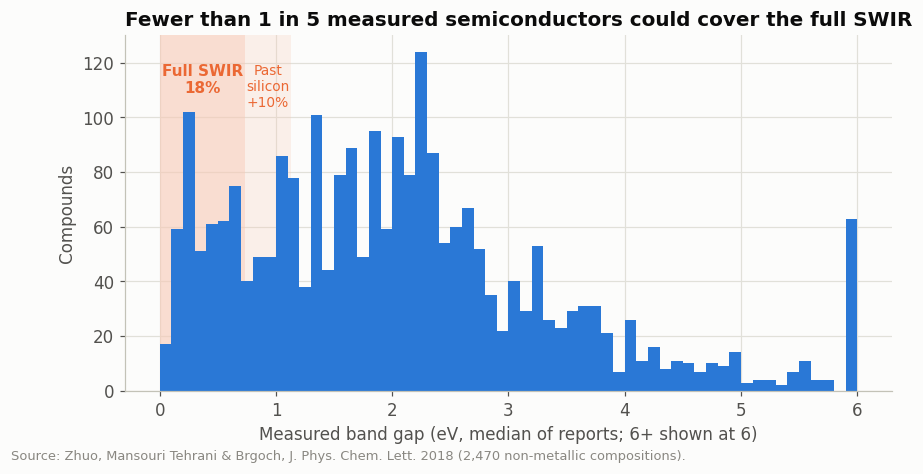

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.axvspan(0, SWIR_EDGE, color=LIGHT_ORANGE, alpha=0.6, lw=0)
ax.axvspan(SWIR_EDGE, SI_EDGE, color=LIGHT_ORANGE, alpha=0.25, lw=0)
ax.hist(gaps["median"].clip(upper=6), bins=np.arange(0, 6.05, 0.1), color=BLUE)
ax.text(SWIR_EDGE / 2, ax.get_ylim()[1] * 0.92, f"Full SWIR\n{pct(audit['share_with_gap_reaching_full_SWIR'])}",
        ha="center", va="top", fontsize=10, color=ORANGE, fontweight="bold")
ax.text((SWIR_EDGE + SI_EDGE) / 2, ax.get_ylim()[1] * 0.92,
        f"Past\nsilicon\n+{pct(audit['share_with_gap_past_silicon'] - audit['share_with_gap_reaching_full_SWIR'])}",
        ha="center", va="top", fontsize=9, color=ORANGE)
ax.set_xlabel("Measured band gap (eV, median of reports; 6+ shown at 6)")
ax.set_ylabel("Compounds")
ax.set_title(f"Fewer than 1 in 5 measured semiconductors could cover the full SWIR")
fig.text(0.01, -0.04, "Source: Zhuo, Mansouri Tehrani & Brgoch, J. Phys. Chem. Lett. 2018 (2,470 non-metallic compositions).",
         fontsize=8.5, color=MUTED)
save(fig, "01_measured_gaps")

**The best-studied semiconductors are missing from the standard benchmark.** Matbench, a widely used machine-learning benchmark for band gaps, removes any compound whose reported gaps span more than 0.1 eV. Most compounds measured more than once disagree by more than that, so the benchmark drops exactly the materials people have measured most.

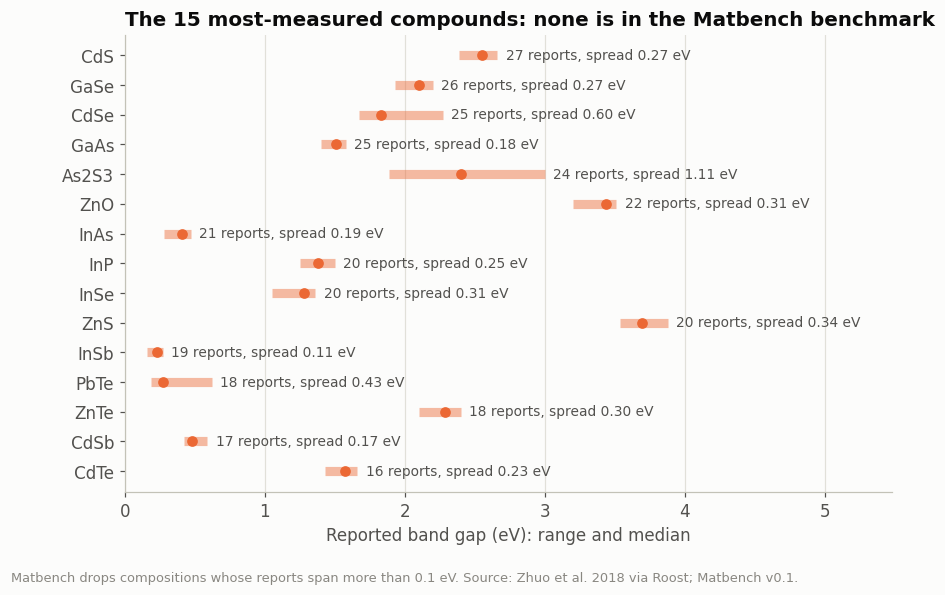

70% of the 454 compounds measured more than once disagree by over 0.1 eV
Matbench keeps 0 of the 25 most-measured compounds


In [7]:
top = gaps.nlargest(15, "n").iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5.4))
y = np.arange(len(top))
ax.hlines(y, top["low"], top["high"], color=ORANGE, lw=6, alpha=0.45)
ax.plot(top["median"], y, "o", color=ORANGE, ms=6)
for yi, (f, r) in zip(y, top.iterrows()):
    ax.text(r["high"] + 0.06, yi, f"{r['n']} reports, spread {r['spread']:.2f} eV", va="center", fontsize=9, color=INK_2)
ax.set_yticks(y, [nice(f) for f in top.index])
ax.set_xlim(0, max(top["high"]) + 1.6)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Reported band gap (eV): range and median")
ax.set_title("The 15 most-measured compounds: none is in the Matbench benchmark")
fig.text(0.01, -0.04, "Matbench drops compositions whose reports span more than 0.1 eV. Source: Zhuo et al. 2018 via Roost; Matbench v0.1.",
         fontsize=8.5, color=MUTED)
save(fig, "02_most_measured_disagree")
print(f"{audit['share_of_repeats_disagreeing_by_over_0.1eV']:.0%} of the {audit['measured_more_than_once']} compounds measured more than once disagree by over 0.1 eV")
print(f"Matbench keeps {audit['top25_most_measured_in_matbench']} of the 25 most-measured compounds")

In [8]:
# Repeated measurements can agree with each other and still be wrong
print("InN reports:", sorted(meas.loc[meas["formula"] == "InN", "Eg"]))
print("Ag2Se in the dataset:", audit["Ag2Se_in_dataset"])

InN reports: [1.95, 2.05, 2.09, 2.1, 2.11, 2.21, 2.4]
Ag2Se in the dataset: False


Two more cautions from the audit:
- **InN.** Every report in the dataset puts indium nitride near 2 eV. Better-quality crystals showed in 2002 that its real gap is about 0.7 eV (Wu *et al.*); the older films were contaminated. The reports agree with each other and are all wrong, so agreement alone doesn't make a value right.
- **Ag₂Se isn't in the dataset at all.** For the model test below, I use 0.15 eV, the room-temperature gap of the orthorhombic bulk phase cited by Hafiz *et al.* (2019), a paper from Sahu's collaboration.

## 5. Teach a model to read band gaps from formulas

**Features.** Each formula becomes 132 numbers using the standard Magpie recipe: averages, ranges and spreads of the elements' properties (electronegativity, atomic size, valence electrons and so on), weighted by composition. No crystal structure is used, which is what lets the model score formulas nobody has made yet.

**A real test.** Sixteen infrared-relevant compounds are held out from all training: the lead and mercury benchmarks (PbS, PbSe, PbTe, HgTe), the III–V and IV–VI semiconductors (InAs, InSb, GaSb, SnTe), and others. Ag₂Se, which no training set contains, is added as a seventeenth test.

In [9]:
ep = ElementProperty.from_preset("magpie")
def featurize(formulas):
    X = np.array([ep.featurize(Composition(f)) for f in formulas], dtype=float)
    return pd.DataFrame(X, index=list(formulas), columns=ep.feature_labels())

HOLDOUT = [reduced(f) for f in ["InAs", "InSb", "GaSb", "PbS", "PbSe", "PbTe", "HgTe", "SnTe",
                                "Bi2Te3", "Bi2Se3", "Ag2S", "AgBiS2", "Mg2Sn", "CdSb", "Sb2Se3", "Cu2Se"]]
EXTERNAL = {"Ag2Se": 0.15}                      # orthorhombic, room temperature (Hafiz et al. 2019)

F = featurize(sorted(set(gaps.index) | set(metal.index) | set(EXTERNAL)))
FILL = F.median()
F = F.fillna(FILL)

train_gap = gaps[~gaps.index.isin(HOLDOUT)]
train_metal = metal[~metal.index.isin(HOLDOUT)]
X_gap, y_gap = F.loc[train_gap.index].values, train_gap["median"].values
X_met, y_met = F.loc[train_metal.index].values, train_metal.values
print(f"Training on {len(y_gap):,} measured gaps and {len(y_met):,} metal/non-metal labels; {len(HOLDOUT) + len(EXTERNAL)} compounds held out")

Training on 2,454 measured gaps and 4,905 metal/non-metal labels; 17 compounds held out


### 5a. Predicting the gap directly (regression)

In [10]:
cv = KFold(5, shuffle=True, random_state=RANDOM_STATE)
reg = RandomForestRegressor(n_estimators=500, n_jobs=-1, random_state=RANDOM_STATE)
pred_cv = cross_val_predict(reg, X_gap, y_gap, cv=cv)
dummy_cv = cross_val_predict(DummyRegressor(strategy="median"), X_gap, y_gap, cv=cv)

narrow = y_gap <= SWIR_EDGE
reg_scores = {
    "MAE_all_eV": mean_absolute_error(y_gap, pred_cv),
    "MAE_guess_the_median_eV": mean_absolute_error(y_gap, dummy_cv),
    "MAE_on_narrow_gap_compounds_eV": mean_absolute_error(y_gap[narrow], pred_cv[narrow]),
    "median_prediction_for_narrow_gap_compounds_eV": np.median(pred_cv[narrow]),
    "narrow_gap_precision": precision_score(narrow, pred_cv <= SWIR_EDGE),
    "narrow_gap_recall": recall_score(narrow, pred_cv <= SWIR_EDGE),
}
pd.Series(reg_scores)

MAE_all_eV                                       0.410290
MAE_guess_the_median_eV                          1.077763
MAE_on_narrow_gap_compounds_eV                   0.387025
median_prediction_for_narrow_gap_compounds_eV    0.701600
narrow_gap_precision                             0.927711
narrow_gap_recall                                0.534722
dtype: float64

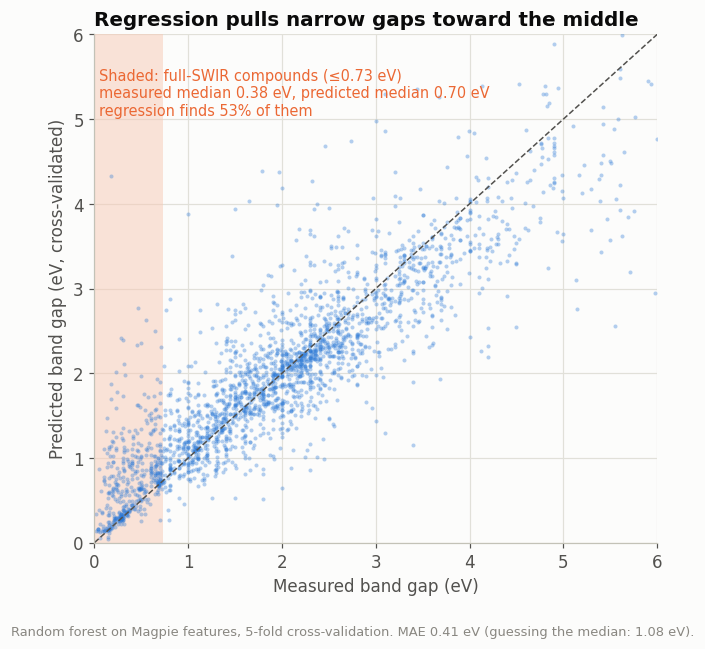

In [11]:
fig, ax = plt.subplots(figsize=(6.6, 6))
ax.axvspan(0, SWIR_EDGE, color=LIGHT_ORANGE, alpha=0.5, lw=0)
ax.scatter(y_gap, pred_cv, s=7, alpha=0.35, color=BLUE, lw=0)
lim = 6
ax.plot([0, lim], [0, lim], color=INK_2, lw=1, ls="--")
ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.set_xlabel("Measured band gap (eV)")
ax.set_ylabel("Predicted band gap (eV, cross-validated)")
ax.set_title("Regression pulls narrow gaps toward the middle")
ax.text(0.05, 5.6, f"Shaded: full-SWIR compounds (≤0.73 eV)\nmeasured median {np.median(y_gap[narrow]):.2f} eV, "
        f"predicted median {reg_scores['median_prediction_for_narrow_gap_compounds_eV']:.2f} eV\n"
        f"regression finds {reg_scores['narrow_gap_recall']:.0%} of them", fontsize=9.5, color=ORANGE, va="top")
fig.text(0.01, -0.03, f"Random forest on Magpie features, 5-fold cross-validation. MAE {reg_scores['MAE_all_eV']:.2f} eV "
         f"(guessing the median: {reg_scores['MAE_guess_the_median_eV']:.2f} eV).", fontsize=8.5, color=MUTED)
save(fig, "03_regression_flattens_extremes")

The regression's typical error is about 0.4 eV, roughly the width of the whole SWIR window. Like most regressions, it hedges toward the average, so it overestimates narrow gaps and misses many of the materials this screen is looking for.

### 5b. Asking the yes/no question directly

Instead of predicting the number, two classifiers each answer a yes/no question:
1. **Is it a metal?** Trained on the experimental metal/non-metal labels.
2. **Is its gap narrow enough for the full SWIR (≤ 0.73 eV)?** Trained on the measured gaps, with the rarer narrow-gap class weighted up.

In [12]:
skf = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
met_clf = RandomForestClassifier(n_estimators=500, n_jobs=-1, random_state=RANDOM_STATE)
p_met_cv = cross_val_predict(met_clf, X_met, y_met, cv=skf, method="predict_proba")[:, 1]

win_clf = RandomForestClassifier(n_estimators=500, n_jobs=-1, random_state=RANDOM_STATE,
                                 class_weight="balanced_subsample", min_samples_leaf=3)
p_win_cv = cross_val_predict(win_clf, X_gap, narrow.astype(int), cv=skf, method="predict_proba")[:, 1]

clf_scores = {
    "metal_accuracy": accuracy_score(y_met, p_met_cv >= 0.5),
    "metal_ROC_AUC": roc_auc_score(y_met, p_met_cv),
    "narrow_gap_precision": precision_score(narrow, p_win_cv >= 0.5),
    "narrow_gap_recall": recall_score(narrow, p_win_cv >= 0.5),
}
pd.Series(clf_scores)

metal_accuracy          0.912334
metal_ROC_AUC           0.971425
narrow_gap_precision    0.764988
narrow_gap_recall       0.738426
dtype: float64

Asked directly, the model finds about three in four narrow-gap compounds instead of about half. The price is more false alarms: about one flag in four is wrong, against fewer than one in ten for the regression. For a first-pass screen that's the right trade, because a missed candidate is gone for good, while a false alarm costs one more check.

Now the real test: compounds the models have never seen.

In [13]:
reg.fit(X_gap, y_gap); met_clf.fit(X_met, y_met); win_clf.fit(X_gap, narrow.astype(int))
test = HOLDOUT + list(EXTERNAL)
Xt = F.loc[test].values
held = pd.DataFrame({
    "measured_gap_eV": [gaps["median"].get(f, EXTERNAL.get(f)) for f in test],
    "regression_gap_eV": reg.predict(Xt),
    "p_narrow": win_clf.predict_proba(Xt)[:, 1],
    "p_metal": met_clf.predict_proba(Xt)[:, 1],
}, index=test)
held["truly_narrow"] = held["measured_gap_eV"] <= SWIR_EDGE
held["flagged_narrow"] = (held["p_narrow"] >= 0.5) & (held["p_metal"] < 0.5)
held["correct"] = held["truly_narrow"] == held["flagged_narrow"]
print(f"Classifier correct on {held['correct'].sum()} of {len(held)} held-out compounds; "
      f"regression MAE on them {mean_absolute_error(held['measured_gap_eV'], held['regression_gap_eV']):.2f} eV")
held.rename(index=nice).sort_values("measured_gap_eV").round(2)

Classifier correct on 14 of 17 held-out compounds; regression MAE on them 0.34 eV


,measured_gap_eV,regression_gap_eV,p_narrow,p_metal,truly_narrow,flagged_narrow,correct
Ag2Se,0.15,0.94,0.57,0.32,True,True,True
HgTe,0.18,1.24,0.73,0.16,True,True,True
InSb,0.23,0.43,0.92,0.16,True,True,True
Bi2Te3,0.25,0.18,0.99,0.01,True,True,True
PbSe,0.26,0.36,0.95,0.01,True,True,True
PbTe,0.27,0.28,0.99,0.07,True,True,True
Mg2Sn,0.30,1.21,0.31,0.66,True,False,False
SnTe,0.33,0.48,0.81,0.10,True,True,True
PbS,0.34,0.88,0.49,0.14,True,False,False
Bi2Se3,0.38,0.52,0.81,0.03,True,True,True


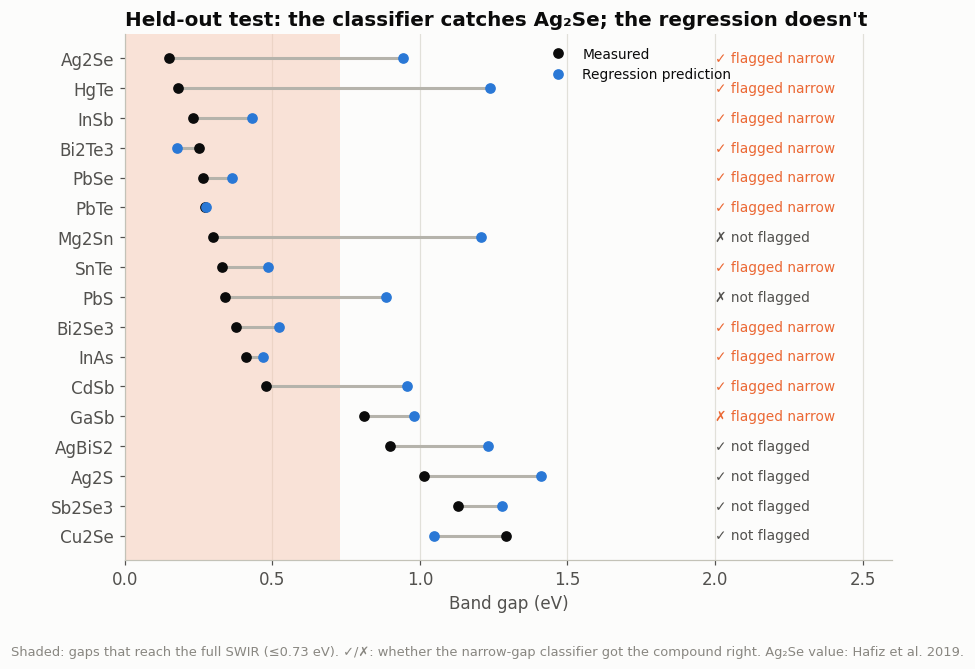

In [14]:
h = held.sort_values("measured_gap_eV", ascending=False)
fig, ax = plt.subplots(figsize=(9, 6.2))
y = np.arange(len(h))
ax.axvspan(0, SWIR_EDGE, color=LIGHT_ORANGE, alpha=0.5, lw=0)
ax.hlines(y, h["measured_gap_eV"], h["regression_gap_eV"], color=GRAY, lw=2)
ax.plot(h["measured_gap_eV"], y, "o", color=INK, ms=6, label="Measured")
ax.plot(h["regression_gap_eV"], y, "o", color=BLUE, ms=6, label="Regression prediction")
for yi, (f, r) in zip(y, h.iterrows()):
    mark = "flagged narrow" if r["flagged_narrow"] else "not flagged"
    ax.text(2.0, yi, ("✓ " if r["correct"] else "✗ ") + mark, va="center", fontsize=9,
            color=ORANGE if r["flagged_narrow"] else INK_2)
ax.set_yticks(y, [nice(f) for f in h.index])
ax.set_xlim(0, 2.6)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Band gap (eV)")
ax.set_title("Held-out test: the classifier catches Ag₂Se; the regression doesn't")
ax.legend(loc="upper left", bbox_to_anchor=(0.53, 1.0), frameon=False, fontsize=9)
fig.text(0.01, -0.03, "Shaded: gaps that reach the full SWIR (≤0.73 eV). ✓/✗: whether the narrow-gap classifier got the compound right. "
         "Ag₂Se value: Hafiz et al. 2019.", fontsize=8.5, color=MUTED)
save(fig, "04_holdout_test")

**14 of 17 right.** The misses are instructive. PbS sits just under the classifier's line, Mg₂Sn gets called a metal, and GaSb (0.81 eV, just outside the window) gets flagged. Ag₂Se is caught, but only just (0.57), so treat it as a close call rather than a confident one. The regression, meanwhile, puts Ag₂Se and HgTe near 1 eV, which would have dropped both from an infrared screen.

## 6. Screen the Materials Project

**The pool.** Every formula in the Materials Project snapshot with at most three elements, after removing RoHS-restricted metals (Pb, Hg, Cd), noble gases and radioactive elements.

**The funnel.**
1. The classifiers call it a non-metal with a gap of 0.73 eV or less.
2. The formula can be charge-balanced with ordinary oxidation states (pymatgen), which weeds out most alloys and intermetallics.
3. **Practical:** no platinum-group metals, gold, rhenium or rare earths (cost and supply), no thallium or beryllium (toxicity), and the metal classifier is fairly confident (p < 0.3).

Featurizing about 40,000 formulas takes a minute or two.

In [15]:
mp["formula"] = mp["formula"].map(reduced)
pool = mp.groupby("formula")["target"].agg(dft_gap_min="min", dft_gap_max="max")
elements = {f: {e.symbol for e in Composition(f).elements} for f in pool.index}

def allowed(f):
    for e in Composition(f).elements:
        if e.symbol in RESTRICTED or e.is_noble_gas or e.is_radioactive or e.Z > 83:
            return False
    return len(elements[f]) <= 3
pool = pool[[allowed(f) for f in pool.index]].copy()
pool["measured"] = pool.index.isin(set(gaps.index) | set(metal.index))

Xp = featurize(pool.index).fillna(FILL).values
pool["p_narrow"] = win_clf.predict_proba(Xp)[:, 1]
pool["p_metal"] = met_clf.predict_proba(Xp)[:, 1]
pool["regression_gap_eV"] = reg.predict(Xp)
print(f"{len(pool):,} lead-, mercury- and cadmium-free formulas scored")

40,459 lead-, mercury- and cadmium-free formulas scored


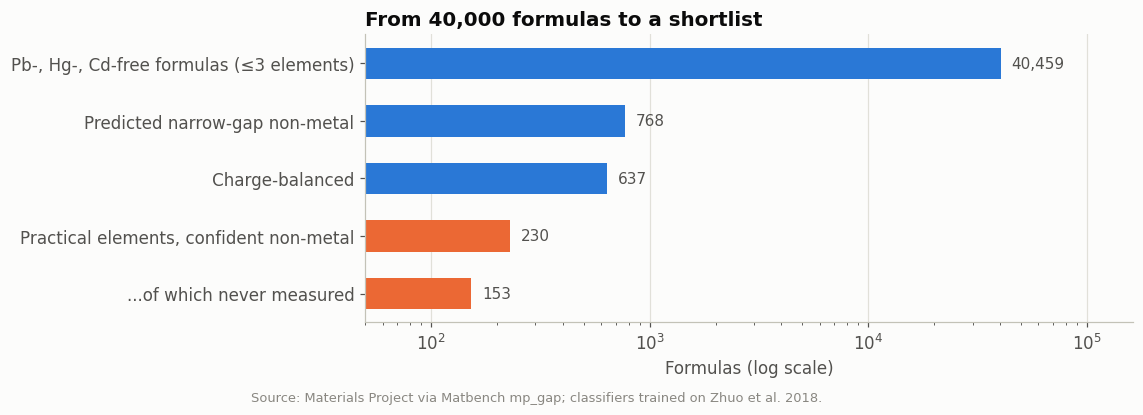

Pb-, Hg-, Cd-free formulas (≤3 elements)    40459
Predicted narrow-gap non-metal                768
Charge-balanced                               637
Practical elements, confident non-metal       230
...of which never measured                    153
dtype: int64

In [16]:
def charge_balanced(f):
    try:
        return len(Composition(f).oxi_state_guesses(max_sites=-50)) > 0
    except Exception:
        return False

PRECIOUS = {"Ru", "Rh", "Pd", "Os", "Ir", "Pt", "Au", "Re"}
RARE_EARTH = {"Sc", "Y", "La", "Ce", "Pr", "Nd", "Sm", "Eu", "Gd", "Tb", "Dy", "Ho", "Er", "Tm", "Yb", "Lu"}
VERY_TOXIC = {"Tl", "Be"}

step1 = pool[(pool["p_narrow"] >= 0.5) & (pool["p_metal"] < 0.5)].copy()
step1["charge_balanced"] = [charge_balanced(f) for f in step1.index]
step2 = step1[step1["charge_balanced"]]
practical = np.array([not (elements[f] & (PRECIOUS | RARE_EARTH | VERY_TOXIC)) for f in step2.index])
step3 = step2[practical & (step2["p_metal"] < 0.3).values]

funnel = pd.Series({
    "Pb-, Hg-, Cd-free formulas (≤3 elements)": len(pool),
    "Predicted narrow-gap non-metal": len(step1),
    "Charge-balanced": len(step2),
    "Practical elements, confident non-metal": len(step3),
    "...of which never measured": int((~step3["measured"]).sum()),
})
fig, ax = plt.subplots(figsize=(9, 3.4))
y = np.arange(len(funnel))[::-1]
ax.barh(y, funnel.values, height=0.55, color=[BLUE, BLUE, BLUE, ORANGE, ORANGE])
for yi, v in zip(y, funnel.values):
    ax.text(v * 1.12, yi, f"{v:,.0f}", va="center", fontsize=10, color=INK_2)
ax.set_yticks(y, funnel.index)
ax.set_xscale("log"); ax.set_xlim(50, funnel.max() * 4)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Formulas (log scale)")
ax.set_title("From 40,000 formulas to a shortlist")
fig.text(0.01, -0.1, "Source: Materials Project via Matbench mp_gap; classifiers trained on Zhuo et al. 2018.", fontsize=8.5, color=MUTED)
save(fig, "05_screen_funnel")
funnel

### What the shortlist is made of

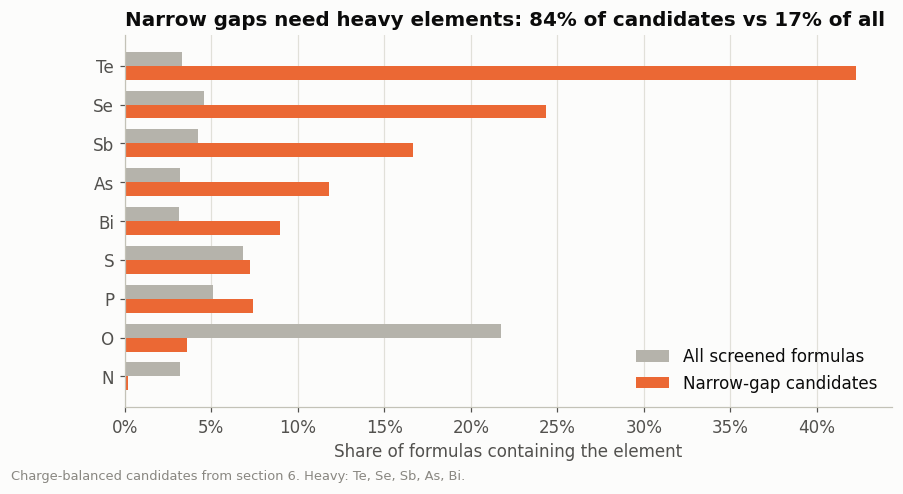

In [17]:
HEAVY = ["Te", "Se", "Sb", "As", "Bi"]
LIGHT = ["S", "P", "O", "N"]
share_with = lambda df, el: np.mean([el in elements[f] for f in df.index])
comp = pd.DataFrame({"All screened formulas": [share_with(pool, e) for e in HEAVY + LIGHT],
                     "Narrow-gap candidates": [share_with(step2, e) for e in HEAVY + LIGHT]},
                    index=HEAVY + LIGHT)
heavy_any = lambda df: np.mean([bool(elements[f] & set(HEAVY)) for f in df.index])
heavy_share = {"pool": heavy_any(pool), "candidates": heavy_any(step2)}

fig, ax = plt.subplots(figsize=(9, 4.4))
y = np.arange(len(comp))[::-1]
ax.barh(y + 0.18, comp["All screened formulas"], height=0.36, color=GRAY, label="All screened formulas")
ax.barh(y - 0.18, comp["Narrow-gap candidates"], height=0.36, color=ORANGE, label="Narrow-gap candidates")
ax.set_yticks(y, comp.index)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="lower right")
ax.set_xlabel("Share of formulas containing the element")
ax.set_title(f"Narrow gaps need heavy elements: {heavy_share['candidates']:.0%} of candidates vs {heavy_share['pool']:.0%} of all")
fig.text(0.01, -0.04, "Charge-balanced candidates from section 6. Heavy: Te, Se, Sb, As, Bi.", fontsize=8.5, color=MUTED)
save(fig, "06_heavy_elements")

**Narrow gaps come from heavy, soft elements.** Big atoms with loosely held outer electrons form weaker bonds, and weaker bonds mean smaller gaps. That's also where the trouble is: tellurium and selenium are byproducts of copper refining with concentrated supply, arsenic and antimony are toxic, and the elements that are both light and benign mostly give wide gaps. There's no free lunch in the infrared.

In [18]:
short = step3[~step3["measured"]].sort_values("p_narrow", ascending=False)
short = short.assign(elements=[", ".join(sorted(elements[f])) for f in short.index])
short[["p_narrow", "p_metal", "regression_gap_eV", "dft_gap_max", "elements"]].head(25).round(2)

,p_narrow,p_metal,regression_gap_eV,dft_gap_max,elements
formula,,,,,
In2SbAs,1.00,0.00,0.11,0.00,"As, In, Sb"
Bi4(TeSe)3,1.00,0.01,0.29,0.36,"Bi, Se, Te"
Bi2TeSe2,0.99,0.00,0.29,0.93,"Bi, Se, Te"
Sn3BiTe4,0.96,0.02,0.24,0.00,"Bi, Sn, Te"
BiSb,0.95,0.23,0.21,0.16,"Bi, Sb"
Bi3Sb,0.95,0.27,0.15,0.24,"Bi, Sb"
Bi2Se,0.95,0.30,0.40,0.00,"Bi, Se"
FeCoSb4,0.94,0.20,0.33,0.00,"Co, Fe, Sb"
FeSb3,0.94,0.24,0.42,0.00,"Fe, Sb"


The top of the unmeasured list is dominated by a few families: **bismuth tellurides and selenides** (the Bi₂Te₃ family), **cobalt, iron and nickel antimonides** (skutterudites such as CoSb₃ and their relatives), and **manganese silicides**. Anyone who works on thermoelectrics will recognize those names.

## 7. The thermoelectric connection

Thermoelectrics turn heat into electricity, and the best ones also have narrow gaps: theory puts the ideal at roughly 6–10 times the thermal energy, about 0.15–0.25 eV at room temperature (Sofo & Mahan, 1994). To test the overlap, each sample in Starrydata is reduced to its host elements (anything at 5 atomic % or more, so dopants drop out). Then I check how often a formula's elements match a thermoelectric host system.

96% of 55,493 samples parsed into 3,422 host systems
Thermoelectric samples in the Ag–Se system: 90 · In–As: 31


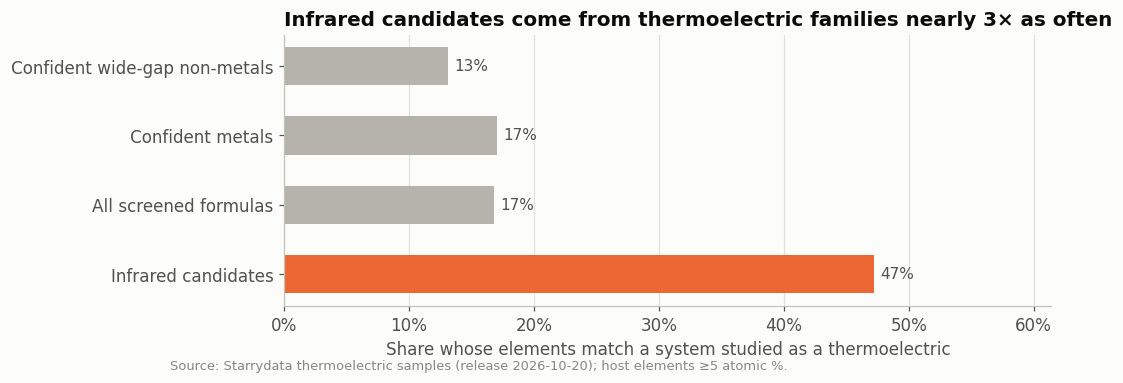

In [19]:
def host(formula, cut=0.05):
    try:
        c = Composition(str(formula).replace(" ", ""))
        frac = c.fractional_composition
        hosts = frozenset(e.symbol for e in c.elements if frac[e] >= cut)
        return hosts or None
    except Exception:
        return None

te["host"] = te["composition"].map(host)
te_systems = set(te["host"].dropna())
in_te = lambda df: np.mean([frozenset(elements[f]) in te_systems for f in df.index])
groups = pd.Series({
    "Confident wide-gap non-metals": in_te(pool[(pool["p_narrow"] < 0.2) & (pool["p_metal"] < 0.3)]),
    "Confident metals": in_te(pool[pool["p_metal"] >= 0.7]),
    "All screened formulas": in_te(pool),
    "Infrared candidates": in_te(step2),
})
host_counts = te["host"].dropna().value_counts()
print(f"{te['host'].notna().mean():.0%} of {len(te):,} samples parsed into {len(te_systems):,} host systems")
print("Thermoelectric samples in the Ag–Se system:", int(host_counts.get(frozenset({"Ag", "Se"}), 0)),
      "· In–As:", int(host_counts.get(frozenset({"In", "As"}), 0)))

fig, ax = plt.subplots(figsize=(9, 3.2))
hbars(ax, groups.index, groups.values, pct, color=[GRAY, GRAY, GRAY, ORANGE])
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("Share whose elements match a system studied as a thermoelectric")
ax.set_title("Infrared candidates come from thermoelectric families nearly 3× as often")
fig.text(0.01, -0.07, "Source: Starrydata thermoelectric samples (release 2026-10-20); host elements ≥5 atomic %.", fontsize=8.5, color=MUTED)
save(fig, "07_thermoelectric_overlap")

Infrared candidates are nearly three times as likely as the pool (47% vs 17%) to come from a thermoelectric family. That fits Sahu's lab well, since it works on both infrared quantum dots and thermoelectrics, and Ag₂Se shows up on both sides.

## 8. Ag₂Se against InAs, with the lead and mercury benchmarks

Measured gaps alone don't settle the choice. This table adds what a company licensing either material would ask about: regulation, toxicity, supply concentration and raw-material cost.

Prices and producer shares are 2025 estimates from the USGS *Mineral Commodity Summaries 2026*. Film cost assumes a 1 cm² film, 500 nm thick, at the bulk density, and counts raw elements only.

In [20]:
LB, OZT = 2.20462, 32.1507
# element: (US$/kg, top producer, share, export controls) — USGS Mineral Commodity Summaries 2026
USGS = {
    "Ag": (38 * OZT, "Mexico", 0.24, "none reported"),
    "In": (380, "China", 0.70, "China, 2025"),
    "As": (1.85 * LB, "Peru", 0.49, "none reported"),
    "Sb": (25 * LB, "China", 0.36, "China 2024; US ban Dec 2024"),
    "Se": (28, "China", 0.53, "none reported"),
    "Te": (120, "China", 0.80, "China end-use checks since Feb 2025"),
    "Pb": (1.06 * LB, "China", 0.42, "none reported"),
}
CONTENDERS = {  # formula: (bulk gap eV, gap source, density g/cm³)
    "Ag2Se": (0.15, "Hafiz et al. 2019", 8.22),
    "InAs": (gaps.loc["InAs", "median"], "dataset median", 5.67),
    "InSb": (gaps.loc["InSb", "median"], "dataset median", 5.78),
    "PbS": (gaps.loc["PbS", "median"], "dataset median", 7.60),
    "HgTe": (gaps.loc["HgTe", "median"], "dataset median*", 8.10),
}
rows = []
for f, (eg, src, rho) in CONTENDERS.items():
    c = Composition(f)
    priced = all(e.symbol in USGS for e in c.elements if e.symbol not in ("S",))
    usd_kg = sum(c.get_wt_fraction(e) * USGS[e.symbol][0] for e in c.elements if e.symbol in USGS) if priced else np.nan
    film_g = 1.0 * 500e-7 * rho                    # 1 cm² × 500 nm (5×10⁻⁵ cm) × density, in grams
    tight = max((USGS[e.symbol] for e in c.elements if e.symbol in USGS), key=lambda u: u[2])
    rows.append({
        "compound": f, "bulk gap (eV)": eg, "gap source": src,
        "longest wavelength, bulk limit (µm)": HC / eg,
        "RoHS": "restricted" if set(map(str, c.elements)) & RESTRICTED else "compliant",
        "most concentrated supply": f"{tight[1]} {tight[2]:.0%}",
        "export controls": tight[3],
        "raw elements (US$/kg)": usd_kg,
        "1 cm² film (US cents)": usd_kg * film_g / 1000 * 100 if priced else np.nan,
        "Starrydata thermoelectric samples": int(host_counts.get(frozenset(map(str, c.elements)), 0)),
    })
h2h = pd.DataFrame(rows).set_index("compound")
h2h.style.format({"bulk gap (eV)": "{:.2f}", "longest wavelength, bulk limit (µm)": "{:.1f}",
                  "raw elements (US$/kg)": "${:,.0f}", "1 cm² film (US cents)": "{:.3f}"}, na_rep="n/a")

,bulk gap (eV),gap source,"longest wavelength, bulk limit (µm)",RoHS,most concentrated supply,export controls,raw elements (US$/kg),1 cm² film (US cents),Starrydata thermoelectric samples
compound,,,,,,,,,
Ag2Se,0.15,Hafiz et al. 2019,8.3,compliant,China 53%,none reported,$902,0.037,90
InAs,0.41,dataset median,3.0,compliant,China 70%,"China, 2025",$232,0.007,31
InSb,0.23,dataset median,5.4,compliant,China 70%,"China, 2025",$213,0.006,58
PbS,0.34,dataset median,3.6,restricted,China 42%,none reported,$2,0.000,211
HgTe,0.18,dataset median*,6.9,restricted,China 80%,China end-use checks since Feb 2025,n/a,n/a,4


\* Bulk HgTe is usually described as a semimetal; the dataset's value likely reflects specific samples or conditions. Sulfur is treated as free, and mercury isn't priced because RoHS restricts it regardless.

**Material cost doesn't decide this.** The raw elements in a 1 cm² detector film cost well under a tenth of a cent, even for silver. What separates the lead-free options is **supply security and regulation**:
- **InAs** depends on indium (70% from China, under Chinese export controls since 2025) and contains arsenic.
- **Ag₂Se** depends on silver, which has the most diverse supply in the table, and selenium (53% China, no controls reported). Its bulk gap is also the narrowest, so in principle it can reach deepest into the infrared.

That is a commercialization argument for Ag₂Se that doesn't depend on detector performance. Performance still has to be compared fairly, with matching bias, wavelength and temperature, and that comparison is the next project.

## 9. What this shows

- **About a fifth of sunlight's energy**, and over a third of its photons, lies past silicon's edge.
- **Benchmark data hides the best-known semiconductors.** Matbench keeps none of the 25 most-measured compounds, because their reports disagree by more than 0.1 eV. Measurements can also agree and still be wrong (InN).
- **Ask the question you care about.** Predicting the gap number underestimates how many narrow-gap materials there are. A yes/no classifier for "narrow enough" finds about three in four, and on the held-out test it catches Ag₂Se, just over the line, while the regression places it near 0.9 eV.
- **The infrared shortlist is a thermoelectrics shortlist.** Most candidates contain Te, Se, Sb, As or Bi, and they are nearly three times as likely as the pool to come from known thermoelectric families. Ag₂Se sits on both sides.
- **For lead-free infrared quantum dots, supply beats price.** Raw materials cost fractions of a cent per detector. Indium's concentration and export controls are a real risk for InAs; silver's diverse supply is a quiet advantage for Ag₂Se.

## 10. Limits

- **Formulas, not crystals.** The models never see structure, so they can't tell polymorphs apart (Ag₂Se changes structure near 133 °C, and its gap changes with it).
- **Bulk gaps are a floor, not a spec.** Detector performance also depends on mobility, traps, surface chemistry and contacts, none of which is modeled.
- **Charge balance is a weak filter.** Some candidates are probably metals in reality.
- **Training data quality.** The labels inherit the literature's errors (InN), and the gaps were measured by different methods and at different temperatures.
- **Snapshot prices.** USGS 2025 estimates move with markets; supply shares and export controls change faster than geology.

In [21]:
summary = {
    "sunlight_energy_past_1100nm": energy_share, "sunlight_photons_past_1100nm": photon_share,
    **{f"audit_{k}": v for k, v in audit.items()},
    **{f"regression_{k}": v for k, v in reg_scores.items()},
    **{f"classifier_{k}": v for k, v in clf_scores.items()},
    "holdout_correct": int(held["correct"].sum()), "holdout_total": len(held),
    "Ag2Se_regression_gap_eV": held.loc["Ag2Se", "regression_gap_eV"], "Ag2Se_p_narrow": held.loc["Ag2Se", "p_narrow"],
    **{f"funnel_{k}": v for k, v in funnel.items()},
    "heavy_element_share_pool": heavy_share["pool"], "heavy_element_share_candidates": heavy_share["candidates"],
    **{f"thermoelectric_share_{k}": v for k, v in groups.items()},
}
pd.Series(summary).to_csv("project03_summary.csv", header=["value"])
pd.Series(summary)

sunlight_energy_past_1100nm                                 0.195739
sunlight_photons_past_1100nm                                0.369147
audit_measurements                                              3895
audit_compositions                                              2470
audit_measured_more_than_once                                    454
audit_median_spread_of_repeats_eV                               0.18
audit_share_of_repeats_disagreeing_by_over_0.1eV            0.696035
audit_share_with_gap_reaching_full_SWIR                     0.179352
audit_share_with_gap_past_silicon                           0.277733
audit_top25_most_measured_in_matbench                              0
audit_Ag2Se_in_dataset                                         False
regression_MAE_all_eV                                        0.41029
regression_MAE_guess_the_median_eV                          1.077763
regression_MAE_on_narrow_gap_compounds_eV                   0.387025
regression_median_prediction_for_n

## Sources

**Data**
- Zhuo, Y., Mansouri Tehrani, A. & Brgoch, J. Predicting the band gaps of inorganic solids by machine learning. *J. Phys. Chem. Lett.* 9, 1668–1673 (2018), [doi:10.1021/acs.jpclett.8b00124](https://doi.org/10.1021/acs.jpclett.8b00124). Copy used: [Roost repository](https://github.com/CompRhys/roost) (MIT license).
- Dunn, A., Wang, Q., Ganose, A., Dopp, D. & Jain, A. Benchmarking materials property prediction methods: the Matbench test set and Automatminer reference algorithm. *npj Comput. Mater.* 6, 138 (2020), [doi:10.1038/s41524-020-00406-3](https://doi.org/10.1038/s41524-020-00406-3). Copies used: [CrabNet repository](https://github.com/anthony-wang/CrabNet).
- Jain, A. *et al.* The Materials Project. *APL Mater.* 1, 011002 (2013), [doi:10.1063/1.4812323](https://doi.org/10.1063/1.4812323). CC BY 4.0.
- Katsura, Y. *et al.* Starrydata: from published plots to shared materials data. *Sci. Technol. Adv. Mater.: Methods* (2025), [doi:10.1080/27660400.2025.2506976](https://doi.org/10.1080/27660400.2025.2506976). [Datasets](https://github.com/starrydata/starrydata_datasets).
- ASTM G173-03 reference solar spectrum, via [pvlib](https://pvlib-python.readthedocs.io).
- U.S. Geological Survey. *Mineral Commodity Summaries 2026* (silver, indium, arsenic, antimony, selenium, tellurium, lead).

**Methods**
- Ward, L., Agrawal, A., Choudhary, A. & Wolverton, C. A general-purpose machine learning framework for predicting properties of inorganic materials. *npj Comput. Mater.* 2, 16028 (2016) (Magpie features), via [matminer](https://hackingmaterials.lbl.gov/matminer/).
- Ong, S.P. *et al.* Python Materials Genomics (pymatgen). *Comput. Mater. Sci.* 68, 314–319 (2013).
- Sofo, J.O. & Mahan, G.D. Optimum band gap of a thermoelectric material. *Phys. Rev. B* 49, 4565 (1994).

**Context**
- Paul, S.J., Li, L., Li, Z., Kywe, T., Vataj, A. & Sahu, A. Heavy metal free Ag₂Se quantum dot inks for near to short-wave infrared detection. *ACS Appl. Mater. Interfaces* (2025), [PMC12464908](https://pmc.ncbi.nlm.nih.gov/articles/PMC12464908).
- Hafiz, S.B., Scimeca, M.R., Zhao, P., Paredes, I.J., Sahu, A. & Ko, D.-K. Silver selenide colloidal quantum dots for mid-wavelength infrared photodetection. *ACS Appl. Nano Mater.* 2, 1631–1636 (2019).
- Song, W. *et al.* (imec). RoHS-compliant InAs CQD photodiodes for SWIR imaging. MATSUS Spring 2026, [abstract](https://www.nanoge.org/proceedings/MATSUSSpring26/692868d050ea410a937b2cf7).
- Wu, J. *et al.* Unusual properties of the fundamental band gap of InN. *Appl. Phys. Lett.* 80, 3967 (2002).
- Pang, H. Quantum dot technology is enabling machine vision applications. *Vision Systems Design*, [article](https://www.vision-systems.com/cameras-accessories/non-visible/article/14303373/quantum-dot-technology-is-enabling-machine-vision-applications).

Code and analysis were developed with help from Claude (Anthropic).